In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [2]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv'

!wget $data -O data-week-3.csv

--2026-10-17 09:28:11--  https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.111.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 977501 (955K) [text/plain]
Saving to: ‘data-week-3.csv’

data-week-3.csv     100%[===================>] 954.59K  --.-KB/s    in 0.08s   

2026-10-17 09:28:12 (12.2 MB/s) - ‘data-week-3.csv’ saved [977501/977501]



# back to the trained model of lesson 3

In [3]:
# we load the data and clean it
df = pd.read_csv('data-week-3.csv')

df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')
df.totalcharges = df.totalcharges.fillna(0)

df.churn = (df.churn == 'yes').astype(int)

# we split the data into train, validation and test
from sklearn.model_selection import train_test_split
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)


# We keep 3 numerical features (tenure, monthlycharges, totalcharges) and 16 categorical ones
numerical = ['tenure', 'monthlycharges', 'totalcharges']

categorical = [
    'gender',
    'seniorcitizen',
    'partner',
    'dependents',
    'phoneservice',
    'multiplelines',
    'internetservice',
    'onlinesecurity',
    'onlinebackup',
    'deviceprotection',
    'techsupport',
    'streamingtv',
    'streamingmovies',
    'contract',
    'paperlessbilling',
    'paymentmethod',
]

# one-hot encode them with DictVectorizer(sparse=False)
from sklearn.feature_extraction import DictVectorizer
dv = DictVectorizer(sparse=False)
dicts_full_train = df_full_train[categorical + numerical].to_dict(orient='records')
X_full_train = dv.fit_transform(dicts_full_train)
y_full_train = df_full_train.churn.values


In [4]:
X_full_train

array([[0.00000e+00, 0.00000e+00, 1.00000e+00, ..., 0.00000e+00,
        1.20000e+01, 2.58350e+02],
       [0.00000e+00, 1.00000e+00, 0.00000e+00, ..., 1.00000e+00,
        4.20000e+01, 3.16055e+03],
       [0.00000e+00, 0.00000e+00, 1.00000e+00, ..., 1.00000e+00,
        7.10000e+01, 4.68175e+03],
       ...,
       [1.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        2.80000e+01, 2.97950e+03],
       [1.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        2.00000e+00, 1.14100e+02],
       [0.00000e+00, 0.00000e+00, 1.00000e+00, ..., 1.00000e+00,
        1.60000e+01, 1.11485e+03]], shape=(5634, 45))

In [5]:
y_full_train

array([0, 1, 0, ..., 1, 1, 0], shape=(5634,))

In [6]:
# train a logistic regression model.
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(solver='lbfgs')
model.fit(X_full_train, y_full_train)


val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)
y_val = df_val.churn.values

y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)
(y_val == churn_decision).mean()

/workspaces/ml-zoomcamp-homework/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


np.float64(0.8041163946061036)

# Accuracy

In [7]:
# Our validation set has 1409 customers:
len(y_val)

1409

In [8]:
# manually calculating the accuracy
(y_val == churn_decision).mean()

np.float64(0.8041163946061036)

In [9]:
#calculatin the accuracy using sklearn
from sklearn.metrics import accuracy_score

accuracy_score(y_val, y_pred >= 0.5)

0.8041163946061036

## Checking different thresholds

In [10]:
thresholds = np.linspace(0, 1, 21)

scores = []

for t in thresholds:
    score = accuracy_score(y_val, y_pred >= t)
    print('%.2f %.3f' % (t, score))
    scores.append(score)

0.00 0.274
0.05 0.503
0.10 0.599
0.15 0.664
0.20 0.725
0.25 0.749
0.30 0.766
0.35 0.776
0.40 0.794
0.45 0.796
0.50 0.804
0.55 0.815
0.60 0.806
0.65 0.788
0.70 0.778
0.75 0.745
0.80 0.737
0.85 0.727
0.90 0.726
0.95 0.726
1.00 0.726


# The dummy model

In [11]:
from collections import Counter

Counter(y_pred >= 1.0)

Counter({np.False_: 1409})

In [12]:
# What accuracy does this dummy model get? The answer is the fraction of customers who did not churn:
1 - y_val.mean()

np.float64(0.7260468417317246)

# 05. TPR and FPR at all thresholds

In [ ]:
def calculate_roc_scores(y_val, y_pred):
    scores = []

    thresholds = np.linspace(0, 1, 101)

    for t in thresholds:
        actual_positive = (y_val == 1)
        actual_negative = (y_val == 0)
        
        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)

        tp = (predict_positive & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()

        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()
        
        scores.append((t, tp, fp, fn, tn))

    columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
    df_scores = pd.DataFrame(scores, columns=columns)

    df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

    return df_scores


def plot_roc_curve(df_scores):
    plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR')
    plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR')
    plt.xlabel('Threshold')
    plt.ylabel('Rate')
    plt.legend()

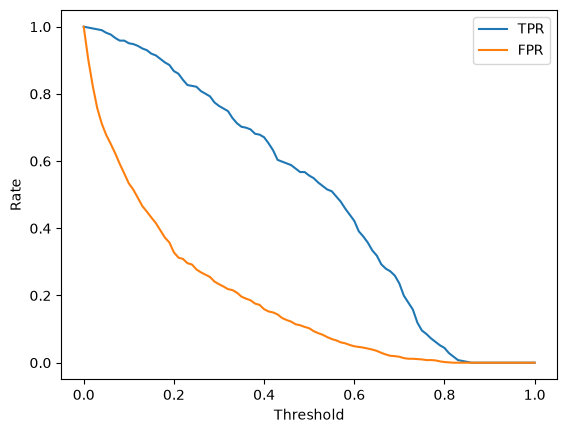

In [33]:
df_scores = calculate_roc_scores(y_val, y_pred)

plot_roc_curve(df_scores)

## The random model

In [34]:
np.random.seed(1)
y_rand = np.random.uniform(0, 1, size=len(y_val))

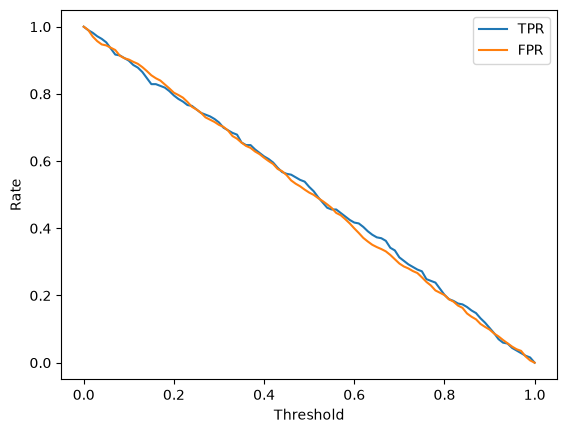

In [35]:
df_scores_rand = calculate_roc_scores(y_val, y_rand)
plot_roc_curve(df_scores_rand)


## The ideal model

In [41]:
# sort the customers so all 1023 negatives come first,
# then all 386 positives,
# and give them scores evenly spread from 0 to 1

num_neg = (y_val == 0).sum()
num_pos = (y_val == 1).sum()

y_ideal = np.repeat([0, 1], [num_neg, num_pos])
y_ideal_pred = np.linspace(0, 1, len(y_val))

In [46]:
# Where should we put the threshold? At the fraction of negatives:
threshold = num_neg / len(y_val)
threshold

np.float64(0.7260468417317246)

In [43]:
# This gives `1.0` - perfect predictions
accuracy_score(y_ideal, y_ideal_pred >= threshold)

1.0

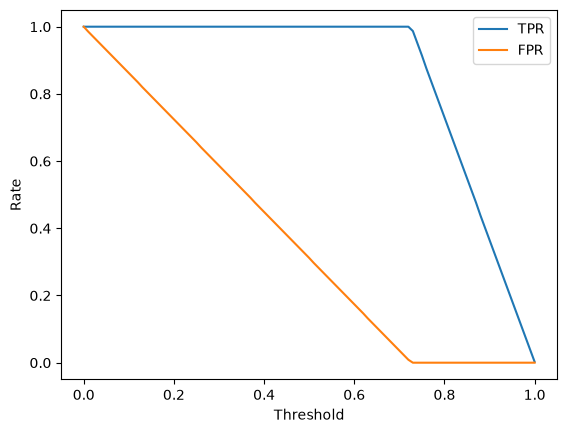

In [ ]:
df_scores_ideal_pred = calculate_roc_scores(y_ideal, y_ideal_pred)

plot_roc_curve(df_scores_ideal_pred)

In [49]:
df_scores_ideal_pred['tpr']

0      1.000000
1      1.000000
2      1.000000
3      1.000000
4      1.000000
         ...   
96     0.147668
97     0.111399
98     0.075130
99     0.038860
100    0.002591
Name: tpr, Length: 101, dtype: float64

In [50]:
df_scores_ideal_pred['fpr']

0      1.000000
1      0.985337
2      0.971652
3      0.957967
4      0.944282
         ...   
96     0.000000
97     0.000000
98     0.000000
99     0.000000
100    0.000000
Name: fpr, Length: 101, dtype: float64

## Putting everything together

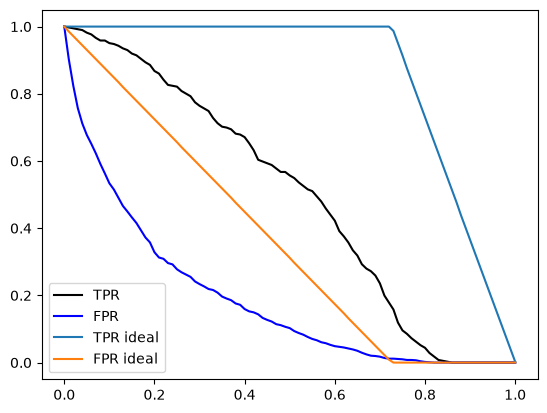

In [48]:
plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR', color='black')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR', color='blue')

plt.plot(df_scores_ideal_pred.threshold, df_scores_ideal_pred['tpr'], label='TPR ideal')
plt.plot(df_scores_ideal_pred.threshold, df_scores_ideal_pred['fpr'], label='FPR ideal')

plt.legend()

## The ROC curve

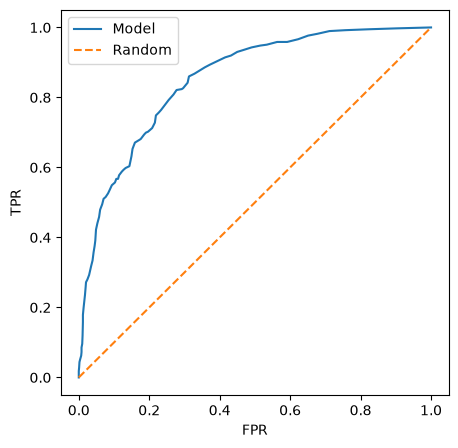

In [51]:
plt.figure(figsize=(5, 5))

plt.plot(df_scores.fpr, df_scores.tpr, label='Model')
plt.plot([0, 1], [0, 1], label='Random', linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

## ROC curves with scikit-learn

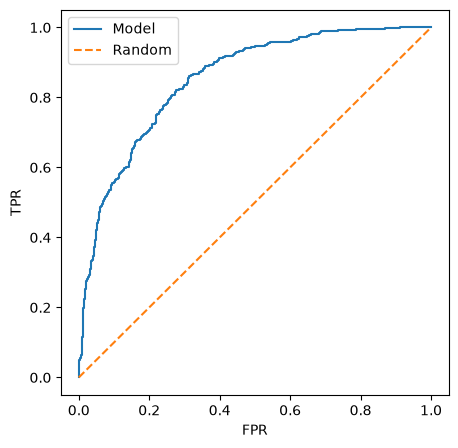

In [52]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_val, y_pred)

plt.figure(figsize=(5, 5))

plt.plot(fpr, tpr, label='Model')
plt.plot([0, 1], [0, 1], label='Random', linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()